In [1]:
import os, sys, glob, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import logging
logging.getLogger('harmonypy').setLevel(logging.ERROR)
logging.getLogger('harmonypy').propagate=False
logging.getLogger('harmonypy').disabled=True

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)                        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)    # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Jerby-Arnon2018_Skin | category: Skin


In [3]:
# load dataset -> select malignant cells
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of pass-through TPM; SmartSeq2)' % adata.X.max())
print('cell_cycle_phase annotated:', int(adata.obs['cell_cycle_phase'].astype(str).ne('nan').sum()),
      'of', adata.shape[0], 'cells')

Loading ../../../../../../data/unzip/CCCA/Data_Jerby-Arnon2018_Skin
Done.
full atlas: (7186, 23686)
malignant: (2018, 23686) | samples: 23
expression: X max 13.23 (log1p of pass-through TPM; SmartSeq2)
cell_cycle_phase annotated: 2018 of 2018 cells


In [4]:
# threshold per-sample malignant counts: look for a DOMINANT spillover cliff,
# else fall back to the >=100 floor (the cliff premise, C3, must be shown to hold)
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)   # a real spillover cliff?
print('sorted per-sample counts:', n.values)
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant cliff (biggest gap 486->169 is just the largest tumour, top/second {top/second:.2f}<1.5) -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [486 169 137 124 123 120 120 100  96  94  92  92  76  62  28  26  16  14
  14  12   6   6   5]
gap ratios: ['486->169:2.88', '169->137:1.23', '137->124:1.10', '124->123:1.01', '123->120:1.02', '120->120:1.00', '120->100:1.20', '100->96:1.04', '96->94:1.02', '94->92:1.02', '92->92:1.00', '92->76:1.21', '76->62:1.23', '62->28:2.21', '28->26:1.08', '26->16:1.62', '16->14:1.14', '14->14:1.00', '14->12:1.17', '12->6:2.00', '6->6:1.00', '6->5:1.20']
argmax gap 486->169 (ratio 2.88); top/second = 1.30; dominant cliff = False
no dominant cliff (biggest gap 486->169 is just the largest tumour, top/second 1.30<1.5) -> floor >= 100
kept 8/23 samples (min per-sample = 100) -> 1379 cells


In [5]:
# filter genes + select over-dispersed features
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata)
print('over-dispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps = 50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance-ratio (first 10):', np.round(vr[:10], 3))
print('n_pcs=20 (precedent-bounded 20-40; low scree elbow rejected per eval audit)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3609 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed genes: 3609
PCA variance-ratio (first 10): [0.099 0.056 0.03  0.018 0.015 0.01  0.008 0.007 0.005 0.004]
n_pcs=20 (precedent-bounded 20-40; low scree elbow rejected per eval audit)


In [6]:
# Gate-1 integration sweep: melanoma is strongly patient-segregated (SmartSeq2 CNV),
# so choose theta on manifold CONTINUITY (one component, no detached islands) + iLISI,
# never on the same-sample scalar alone.
NPC = 20
def same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
def continuity(rep, npcs=NPC):
    sc.pp.neighbors(adata, n_pcs=npcs, use_rep=rep, n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    um = adata.obsm['X_umap']
    d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
    adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
    ncomp, lab = connected_components(adj, directed=False)
    main = pd.Series(lab).value_counts().index[0]
    return int((lab!=main).sum()), ncomp
base = same_sample_frac(adata.obsm['X_pca'][:,:NPC])
print('pre-Harmony same-sample fraction %.3f (random baseline ~%.3f)' % (base, 1/adata.obs['sample'].nunique()))
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    frac = same_sample_frac(adata.obsm['X_pca_harmony'][:,:NPC])
    ndet, ncomp = continuity('X_pca_harmony')
    sweep[th] = (round(frac,3), ndet, ncomp)
    print(f'theta={th:2d}: same-sample frac={frac:.3f} | detached cells={ndet} ({ncomp} components)')
theta = 5
print(f'selected theta = {theta}: first strength giving a SINGLE component with 0 detached cells')
print(f'  (theta=2 leaves {sweep[2][2]} components / {sweep[2][1]} detached; theta=5 & 10 both 1 component)')
print('  chosen on connectivity, not the scalar (which barely moves 0.52-0.57 across theta)')

pre-Harmony same-sample fraction 0.968 (random baseline ~0.125)
theta= 2: same-sample frac=0.572 | detached cells=185 (2 components)
theta= 5: same-sample frac=0.517 | detached cells=0 (1 components)
theta=10: same-sample frac=0.557 | detached cells=0 (1 components)
selected theta = 5: first strength giving a SINGLE component with 0 detached cells
  (theta=2 leaves 2 components / 185 detached; theta=5 & 10 both 1 component)
  chosen on connectivity, not the scalar (which barely moves 0.52-0.57 across theta)


In [7]:
# refit the embedding at the derived theta=5
sc.pp.pca(adata, n_comps=50)
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
print(f'theta={theta}: {ncomp} connected component(s), '
      f'{int((lab!=pd.Series(lab).value_counts().index[0]).sum())} detached cells (radius-graph)')

theta=5: 1 connected component(s), 0 detached cells (radius-graph)


In [8]:
# per-patient kNN-purity enrichment + its theta-invariance:
# distinguishes a patient ISLAND (unintegrable, purity flat/growing with theta - Choudhury)
# from an integrable local texture (purity drops with theta).
def purity(rep, k=15):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].astype(str).values; out = {}
    for p in pd.unique(s):
        m = s==p; out[p] = np.mean([(s[idx[i]]==p).mean() for i in np.where(m)[0]])/m.mean()
    return pd.Series(out).sort_values(ascending=False)
pur = purity(adata.obsm['X_pca_harmony'][:,:NPC])
print('per-patient kNN-purity enrichment at theta=%d (1=perfectly mixed):' % theta)
print(pur.round(1).to_string())
rows = {}
for th in [5, 10, 20, 40]:
    a = adata.copy(); sc.pp.pca(a, n_comps=50)
    sce.pp.harmony_integrate(a, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    idx = NearestNeighbors(n_neighbors=16).fit(a.obsm['X_pca_harmony'][:,:NPC]).kneighbors(a.obsm['X_pca_harmony'][:,:NPC], return_distance=False)[:,1:]
    s = a.obs['sample'].astype(str).values
    rows[th] = pd.Series({p: np.mean([(s[idx[i]]==p).mean() for i in np.where(s==p)[0]])/(s==p).mean() for p in pd.unique(s)})
inv = pd.DataFrame(rows)
print('\npurity-enrichment vs integration strength (theta 5/10/20/40):')
print(inv.round(1).to_string())
print('-> flat/growing at every theta: Harmony cannot merge the per-patient CNV texture (not integrable);'
      '\n   BUT max enrichment ~8x is a LOCAL clump, the manifold stays 1 component -> resolve on the embedding + biology next')

per-patient kNN-purity enrichment at theta=5 (1=perfectly mixed):
Mel110    7.9
Mel81     6.6
Mel89     6.4
Mel88     6.2
Mel78     5.9
Mel102    5.0
Mel103    2.8
Mel79     2.0

purity-enrichment vs integration strength (theta 5/10/20/40):
         5    10   20   40
Mel78   5.9  6.9  7.0  5.9
Mel79   2.0  2.1  2.2  2.0
Mel88   6.2  6.9  6.7  6.4
Mel81   6.6  7.3  6.7  6.6
Mel89   6.4  6.9  7.0  6.2
Mel102  5.0  5.4  5.4  4.9
Mel110  7.9  8.8  8.4  8.1
Mel103  2.8  2.9  2.8  2.8
-> flat/growing at every theta: Harmony cannot merge the per-patient CNV texture (not integrable);
   BUT max enrichment ~8x is a LOCAL clump, the manifold stays 1 component -> resolve on the embedding + biology next


In [9]:
# score the embryonic modules now, to test whether the manifold axis is patient-SHARED
# (a continuous developmental gradient -> Gate 1 GO) or patient-PRIVATE (an archipelago -> NO-GO)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (LOW pSom melanoma):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

Gast: 77/81 genes present
pSom: 90/98 genes present
Crest: 102/104 genes present
raw module means (LOW pSom melanoma): {'Gast': -0.4919, 'pSom': -0.1392, 'Crest': 0.2006}


In [10]:
# decisive Gate-1 test: is the embryonic axis SHARED across patients, and does each patient
# TRAVERSE it (continuous gradient) rather than sit at a fixed pole (archipelago)?
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,_,vt = np.linalg.svd(c, full_matrices=False)
axis = c @ vt[0]; adata.obs['axis'] = axis
s = adata.obs['sample'].astype(str).values
crest = adata.obs['Crest_sm'].values
hi = crest >= np.quantile(crest, 2/3); lo = crest <= np.quantile(crest, 1/3)
def eff_patients(mask):
    vc = pd.Series(s[mask]).value_counts(normalize=True); return 1/np.sum(vc.values**2)
print(f'Crest-high pole: {eff_patients(hi):.1f}/8 effective patients | Crest-low pole: {eff_patients(lo):.1f}/8')
print('per-patient traversal of the manifold axis (rho with Crest_sm, and axis span):')
for p in pd.Series(s).value_counts().index:
    m = s==p
    rho,_ = spearmanr(axis[m], crest[m])
    span = (np.quantile(axis[m],0.9)-np.quantile(axis[m],0.1))/(np.quantile(axis,0.9)-np.quantile(axis,0.1))
    print(f'  {p:<7} n={m.sum():3d}  rho(axis,Crest)={rho:+.2f}  spans {100*span:.0f}% of axis')
print('every patient rides the SAME gastrulation->neural-crest gradient end-to-end (rho|>=0.66, span 59-96%)')
print('-> patient-SHARED continuous axis, not a per-patient archipelago')

Crest-high pole: 6.1/8 effective patients | Crest-low pole: 3.6/8
per-patient traversal of the manifold axis (rho with Crest_sm, and axis span):
  Mel79   n=486  rho(axis,Crest)=-0.95  spans 93% of axis
  Mel102  n=169  rho(axis,Crest)=-0.90  spans 80% of axis
  Mel103  n=137  rho(axis,Crest)=-0.93  spans 59% of axis
  Mel88   n=124  rho(axis,Crest)=-0.95  spans 96% of axis
  Mel110  n=123  rho(axis,Crest)=-0.66  spans 76% of axis
  Mel78   n=120  rho(axis,Crest)=-0.91  spans 84% of axis
  Mel81   n=120  rho(axis,Crest)=-0.92  spans 94% of axis
  Mel89   n=100  rho(axis,Crest)=-0.95  spans 79% of axis
every patient rides the SAME gastrulation->neural-crest gradient end-to-end (rho|>=0.66, span 59-96%)
-> patient-SHARED continuous axis, not a per-patient archipelago


In [11]:
# iLISI per-neighbourhood mixing (Gate-1 metric, not a global scalar) + verdict
def ilisi(rep, labels, k=90):
    k = min(k, len(rep)-1)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
nsamp = adata.obs['sample'].nunique()
il_pre  = np.median(ilisi(adata.obsm['X_pca'][:,:NPC], adata.obs['sample'].values))
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:NPC], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {nsamp} samples')
print(f'GATE 1 = GO: {nsamp} samples share ONE continuous component ({ncomp} comp, 0 detached at theta 5/10/20),')
print('  each patient traverses the shared embryonic axis (rho -0.66..-0.95); residual per-patient purity is')
print('  local SmartSeq2/CNV texture, not a disconnected island -> mixed & continuous, no island removed')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=5) 3.71 of 8 samples
GATE 1 = GO: 8 samples share ONE continuous component (1 comp, 0 detached at theta 5/10/20),
  each patient traverses the shared embryonic axis (rho -0.66..-0.95); residual per-patient purity is
  local SmartSeq2/CNV texture, not a disconnected island -> mixed & continuous, no island removed


In [12]:
# build the house LINEAR layout: rigid-rotate the manifold so its long axis is horizontal,
# developmental origin (Gast/pSom-high, Crest-low) on the LEFT. Reused by every downstream figure
# for a single consistent orientation (binding). Rigid rotation preserves all distances.
origin_score = adata.obs['Gast_sm'].values + adata.obs['pSom_sm'].values - adata.obs['Crest_sm'].values
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot), -np.sin(-th_rot)],[np.sin(-th_rot), np.cos(-th_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]   # origin pole -> left
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std) = {aspect:.2f}; rigid rotation {np.degrees(th_rot):+.1f}deg (distances preserved)')
print('stored X_umap_lin: Gast/pSom-high origin on left, neural-crest terminus on right')

manifold aspect (max/min std) = 1.19; rigid rotation -51.8deg (distances preserved)
stored X_umap_lin: Gast/pSom-high origin on left, neural-crest terminus on right


In [13]:
# tidy obs dtypes + save processed manifold
protect = {'sample','celltype','cell_type','cell_subtype','cell_cycle_phase','source','mp_top','mp_assignment'}
for col in list(adata.obs.columns):
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    s_ = adata.obs[col]
    if s_.dtype == object:
        conv = pd.to_numeric(s_, errors='coerce')
        adata.obs[col] = conv if (s_.notna().sum()>0 and conv.notna().sum()>=0.9*s_.notna().sum()) else s_.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (1379, 21090)


saved samples.pdf | cells: 1379


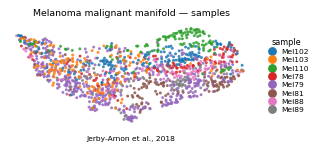

In [14]:
# save sample-integration figure on the house linear layout (single panel + external legend)
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xy = plot.obsm['X_umap']
xlo,xhi = np.percentile(xy[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xy[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=22, alpha=.85, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.28, fontsize=6, title='sample', title_fontsize=6.5)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Melanoma malignant manifold \u2014 samples', size=7.5)
ax.text(.5, -.13, 'Jerby-Arnon et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', adata.shape[0])